# Step 5 — Who does it shoot?

Step 4 built instruments that measure **outcomes**: who survived, how often, with what
error bar. This step builds the one instrument that measures **behaviour**.

The reason it needs to exist is a limitation of the outcome measures, and it is not a
small one. **A flat survival profile — everyone winning about $1/N$ of the time — is
produced by two completely different policies:**

- an equilibrium that happens to be near-uniform, and
- a policy that learned nothing and discriminates on nothing.

The survival numbers are the same. More episodes shrink the error bars around *both*
and never separate them. What separates them is **who the agent shoots**.

Three things get built here:

1. **The eligibility rules** — the three conditions that make a shot countable, named
   once because they are the whole honesty guarantee.
2. **Targeting by accuracy rank** — calibrated at N=3, where the right answer is known
   in advance.
3. **Targeting by how many players remain** — which **N=3 cannot exercise at all**, for
   a reason worth understanding, so it is calibrated at N=5.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn

from gruel_env import GruelEnv, MISS, SHOOT_LEFT, SHOOT_RIGHT, N_ACTIONS

SEED = 0
GAME_SEED = 1000 + SEED
TORCH_SEED = 2000 + SEED

rng = np.random.default_rng(SEED)
torch.manual_seed(TORCH_SEED)
torch.set_num_threads(1)

EXACT_N3 = {0.4: 10 / 27, 0.6: 9 / 27, 0.8: 8 / 27}

print("torch", torch.__version__)
print("exact N=3 survival:", {a: round(v, 5) for a, v in EXACT_N3.items()})

torch 2.2.2
exact N=3 survival: {0.4: 0.37037, 0.6: 0.33333, 0.8: 0.2963}


## The policies

Six rules. The first four behave in ways that need no measurement to predict, which is
what makes them able to test an instrument. The last two are **built deliberately** to
have a property the instrument is supposed to detect.

In [2]:
def shoot_strongest(game, actor):
    """Always fire at whichever neighbour shoots better."""
    left, right = game.neighbours(actor)
    if game.accuracies[left] >= game.accuracies[right]:
        return SHOOT_LEFT
    return SHOOT_RIGHT


def shoot_weakest(game, actor):
    """Always fire at whichever neighbour shoots worse."""
    left, right = game.neighbours(actor)
    if game.accuracies[left] <= game.accuracies[right]:
        return SHOOT_LEFT
    return SHOOT_RIGHT


def always_miss(game, actor):
    """Never fire."""
    return MISS


def coin_flip(game, actor):
    """Always fire, but pick a side without looking at either neighbour."""
    if rng.random() < 0.5:
        return SHOOT_LEFT
    return SHOOT_RIGHT

**`split_by_seat` is built to be misdescribed by a single number.** Even-numbered seats
fire at their stronger neighbour, odd-numbered seats at their weaker one. No player in
this policy is ever undecided: every one of them targets with probability 1.0 or 0.0.
A pooled average will nonetheless land somewhere in the middle, describing a player
that does not exist.

In [3]:
def split_by_seat(game, actor):
    if actor % 2 == 0:
        return shoot_strongest(game, actor)
    return shoot_weakest(game, actor)

**`switch_at_three` is built to depend on how many are alive.** It fires at the weaker
neighbour while four or more remain and at the stronger one once three remain. So its
survivor-count profile is known before it is measured: 0.0, 0.0, then 1.0. An
instrument claiming to detect survivor dependence has to recover that step.

In [4]:
def switch_at_three(game, actor):
    if game.n_alive() <= 3:
        return shoot_strongest(game, actor)
    return shoot_weakest(game, actor)

## Playing episodes, and recording the context *before* the step

Carried forward from step 4 unchanged. The one subtle line is why the neighbours are
recorded before `game.step()` and not after: **a kill contracts the circle.** Once a
player dies the ring re-joins around the gap, so the shooter's neighbours afterwards are
no longer the ones it was choosing between. Reading them after the step would silently
score the decision against the wrong pair.

In [5]:
def play_episodes(game, policy, episodes):
    """Play `episodes` episodes. Returns one record per episode."""
    records = []
    for _ in range(episodes):
        game.reset()
        decisions = []

        for acting_agent in game.agent_iter():
            observation, reward, termination, truncation, info = game.last()

            # A finished agent is handed to us one last time, so PettingZoo can retire
            # it. Stepping with None is how we say 'nothing to do here'.
            if termination or truncation:
                game.step(None)
                continue

            actor = game.position_of_agent[acting_agent]
            action = policy(game, actor)

            # Recorded BEFORE stepping, because a kill contracts the circle.
            left, right = game.neighbours(actor)
            decisions.append({
                "accuracy": round(float(game.accuracies[actor]), 4),
                "action": action,
                "left_accuracy": round(float(game.accuracies[left]), 4),
                "right_accuracy": round(float(game.accuracies[right]), 4),
                "n_alive": game.n_alive(),
            })

            game.step(action)

        if len(game.order) == 1:
            survivor_accuracy = round(float(game.accuracies[game.order[0]]), 4)
        else:
            survivor_accuracy = None

        records.append({
            "survivors": list(game.order),
            "survivor_accuracy": survivor_accuracy,
            "stagnated": game.reason == "stagnation",
            "decisions": decisions,
        })
    return records


def survival_by_accuracy(records):
    """Counted from who is actually alive, never from rewards."""
    wins = {}
    for record in records:
        for decision in record["decisions"]:
            if decision["accuracy"] not in wins:
                wins[decision["accuracy"]] = 0
    for record in records:
        if record["survivor_accuracy"] is not None:
            wins[record["survivor_accuracy"]] = wins[record["survivor_accuracy"]] + 1
    rates = {}
    for accuracy in sorted(wins):
        rates[accuracy] = wins[accuracy] / len(records)
    return rates

## 1. The three eligibility rules

Step 4 applied these inline. They are named here because this step uses them twice —
once per rank and once per survivor count — and because they are the reason the
measurement can be trusted. Each one excludes a decision that *looks* countable and
is not.

In [6]:
def eligible(decision):
    """Whether a recorded decision is a genuine choice between two different neighbours."""
    if decision["action"] == MISS:
        return False        # never fired, so it selected no target at all
    if decision["n_alive"] <= 2:
        return False        # left and right are the same player
    if decision["left_accuracy"] == decision["right_accuracy"]:
        return False        # neither neighbour is the stronger one
    return True


def chose_stronger(decision):
    """Whether the shot went at the better shot of the two neighbours."""
    if decision["action"] == SHOOT_LEFT:
        chosen = decision["left_accuracy"]
        other = decision["right_accuracy"]
    else:
        chosen = decision["right_accuracy"]
        other = decision["left_accuracy"]
    return chosen > other

The first rule is the one that is easy to get wrong, and getting it wrong invents a
result. A policy that never fires has made **no targeting decisions**. If it were
reported as a rate of `0.0` that would be the specific claim *"it always shot the
weaker neighbour"* — a statement about behaviour that never occurred. So the functions
below return `None`, not zero.

In [7]:
def targeting_rate(records, accuracy=None):
    """P(fire at the stronger neighbour). Returns (rate, stronger, decisions).

    `rate` is None when no decision was eligible.
    """
    stronger = 0
    decisions = 0
    for record in records:
        for decision in record["decisions"]:
            if accuracy is not None and decision["accuracy"] != accuracy:
                continue
            if not eligible(decision):
                continue
            decisions = decisions + 1
            if chose_stronger(decision):
                stronger = stronger + 1
    if decisions == 0:
        return None, 0, 0
    return stronger / decisions, stronger, decisions

## 2. Calibrating at N=3, where the answer is known first

At N=3 the exact equilibrium **is** `shoot_strongest` — every player fires at its
stronger neighbour with probability 1.0. That is what makes N=3 the right place to
check the instrument: there is a known answer to disagree with.

In [8]:
CALIBRATION_EPISODES = 4000

game3 = GruelEnv(n=3, reward="terminal", seating="ranked", seed=GAME_SEED)
game3.reset()
print("N=3 seating (position -> accuracy):",
      [round(float(a), 2) for a in game3.accuracies])

calibration = {}
for name, policy in [("shoot_strongest", shoot_strongest),
                     ("shoot_weakest", shoot_weakest),
                     ("coin_flip", coin_flip),
                     ("split_by_seat", split_by_seat),
                     ("switch_at_three", switch_at_three),
                     ("always_miss", always_miss)]:
    fresh = GruelEnv(n=3, reward="terminal", seating="ranked", seed=GAME_SEED)
    calibration[name] = play_episodes(fresh, policy, CALIBRATION_EPISODES)

print()
print("%-18s %12s %11s   %s" % ("policy", "P(stronger)", "decisions", "expected"))
expectations = {
    "shoot_strongest": "1.0 by construction",
    "shoot_weakest": "0.0 by construction",
    "coin_flip": "near 0.5, picks a side blind",
    "split_by_seat": "a middling number describing nobody",
    "switch_at_three": "1.0 -- at N=3 it collapses to shoot_strongest",
    "always_miss": "no data, it never fired",
}
for name in calibration:
    rate, stronger, decisions = targeting_rate(calibration[name])
    if rate is None:
        shown = "no data"
    else:
        shown = format(rate, ".4f")
    print("%-18s %12s %11d   %s" % (name, shown, decisions, expectations[name]))

N=3 seating (position -> accuracy): [0.4, 0.6, 0.8]



policy              P(stronger)   decisions   expected
shoot_strongest          1.0000        6648   1.0 by construction
shoot_weakest            0.0000        6609   0.0 by construction
coin_flip                0.4886        6598   near 0.5, picks a side blind
split_by_seat            0.6661        6598   a middling number describing nobody
switch_at_three          1.0000        6648   1.0 -- at N=3 it collapses to shoot_strongest
always_miss             no data           0   no data, it never fired


The two extremes come out at exactly 1.0 and 0.0, `coin_flip` near a half, and
`always_miss` returns no data rather than a rate. The instrument agrees with every
answer that was known in advance.

## Why a pooled number is not enough — `split_by_seat` broken apart

`split_by_seat` produced a middling pooled figure. Split by rank it is nothing of the
sort: every player is at one extreme or the other. **The pooled average describes a
player that does not exist in the policy.**

In [9]:
print("%-18s %11s %11s %11s   %s"
      % ("policy", "acc 0.4", "acc 0.6", "acc 0.8", "pooled"))
for name in ["shoot_strongest", "coin_flip", "split_by_seat"]:
    cells = []
    for accuracy in [0.4, 0.6, 0.8]:
        rate, stronger, decisions = targeting_rate(calibration[name], accuracy=accuracy)
        if rate is None:
            cells.append("no data")
        else:
            cells.append(format(rate, ".4f"))
    pooled, stronger, decisions = targeting_rate(calibration[name])
    print("%-18s %11s %11s %11s   %s"
          % (name, cells[0], cells[1], cells[2], format(pooled, ".4f")))

print()
print("split_by_seat's per-rank figures are extremes; its pooled figure is neither.")
print("This is why every table below is conditioned rather than averaged.")

policy                 acc 0.4     acc 0.6     acc 0.8   pooled
shoot_strongest         1.0000      1.0000      1.0000   1.0000
coin_flip               0.4870      0.4871      0.4918   0.4886
split_by_seat           1.0000      0.0000      1.0000   0.6661

split_by_seat's per-rank figures are extremes; its pooled figure is neither.
This is why every table below is conditioned rather than averaged.


## And why survival cannot stand in for it

The two measures are **different axes**, and the claim is checked rather than asserted:
the policies are sorted by survival spread and by targeting, and the two orderings are
compared. If they disagree, then neither number can be recovered from the other.

In [10]:
print("%-18s %11s %11s %11s %10s %11s"
      % ("policy", "surv 0.4", "surv 0.6", "surv 0.8", "spread", "P(stronger)"))
for name in calibration:
    rates = survival_by_accuracy(calibration[name])
    values = [rates.get(a, 0.0) for a in [0.4, 0.6, 0.8]]
    spread = max(values) - min(values)
    rate, stronger, decisions = targeting_rate(calibration[name])
    if rate is None:
        shown = "no data"
    else:
        shown = format(rate, ".4f")
    print("%-18s %11.4f %11.4f %11.4f %10.4f %11s"
          % (name, values[0], values[1], values[2], spread, shown))

policy                surv 0.4    surv 0.6    surv 0.8     spread P(stronger)
shoot_strongest         0.3715      0.3325      0.2960     0.0755      1.0000
shoot_weakest           0.0813      0.3172      0.6015     0.5202      0.0000
coin_flip               0.2200      0.3345      0.4455     0.2255      0.4886
split_by_seat           0.2345      0.2742      0.4913     0.2568      0.6661
switch_at_three         0.3715      0.3325      0.2960     0.0755      1.0000
always_miss             0.0000      0.0000      0.0000     0.0000     no data


Sorted both ways. A policy that never fires has no targeting to sort on, so it is left
out rather than given a placeholder position.

In [11]:
comparable = {}
for name in calibration:
    rate, stronger, decisions = targeting_rate(calibration[name])
    if rate is None:
        continue
    rates = survival_by_accuracy(calibration[name])
    values = [rates.get(a, 0.0) for a in [0.4, 0.6, 0.8]]
    comparable[name] = (max(values) - min(values), rate)

by_survival = sorted(comparable, key=lambda name: comparable[name][0])
by_targeting = sorted(comparable, key=lambda name: comparable[name][1])

print("by survival spread:", by_survival)
print("by targeting:      ", by_targeting)
print()
print("same ordering?", by_survival == by_targeting)
print()
if by_survival != by_targeting:
    print("The orderings disagree, so neither measure determines the other. shoot_weakest")
    print("is the MOST differentiated policy by survival and the LOWEST by targeting --")
    print("a policy can spread survival widely while making the opposite choice to the")
    print("one the equilibrium makes.")

by survival spread: ['shoot_strongest', 'switch_at_three', 'coin_flip', 'split_by_seat', 'shoot_weakest']
by targeting:       ['shoot_weakest', 'coin_flip', 'split_by_seat', 'shoot_strongest', 'switch_at_three']

same ordering? False

The orderings disagree, so neither measure determines the other. shoot_weakest
is the MOST differentiated policy by survival and the LOWEST by targeting --
a policy can spread survival widely while making the opposite choice to the
one the equilibrium makes.


## 3. Targeting by how many remain — and why N=3 cannot show it

The equilibrium's targeting is **not one number**. The solver in folder 02 reports that
at N=5 it fires at the stronger neighbour about 40% of the time while five are alive,
50% at four, and 100% once three remain. Pooling those into one average describes a
game nobody plays.

So the same measurement is needed split by survivor count. Written below — and then
immediately shown to be **inert at N=3**, for a reason that follows from the eligibility
rules rather than from anything about policies.

In [12]:
def targeting_by_alive(records):
    """The same measurement, split by how many were alive when the shot was fired."""
    stronger_count = {}
    decision_count = {}

    for record in records:
        for decision in record["decisions"]:
            if not eligible(decision):
                continue
            alive_then = decision["n_alive"]
            if alive_then not in decision_count:
                stronger_count[alive_then] = 0
                decision_count[alive_then] = 0
            decision_count[alive_then] = decision_count[alive_then] + 1
            if chose_stronger(decision):
                stronger_count[alive_then] = stronger_count[alive_then] + 1

    rows = {}
    for alive in sorted(decision_count):
        rows[alive] = (stronger_count[alive] / decision_count[alive],
                       stronger_count[alive],
                       decision_count[alive])
    return rows


rows3 = targeting_by_alive(calibration["shoot_strongest"])
print("shoot_strongest at N=3, split by how many were alive:")
for alive in rows3:
    rate, stronger, decisions = rows3[alive]
    print("   %d alive: %.4f   (%d decisions)" % (alive, rate, decisions))

print()
print("rows produced:", len(rows3))

shoot_strongest at N=3, split by how many were alive:
   3 alive: 1.0000   (6648 decisions)

rows produced: 1


**One row.** Not because the policy ignores the survivor count, but because at N=3 no
other row can exist. Play starts with three alive; the first kill leaves two; and a
two-player state is excluded by the second eligibility rule, since a player with two
neighbours that are the *same person* has made no choice between them.

This matters more than it looks. A single row showing no variation would read exactly
like the "discriminates on nothing" signature — flat, no survivor dependence. It is
nothing of the kind: **there is no second row to differ from.** The instrument is not
reporting flatness, it is reporting that the question cannot be asked here.

In [13]:
alive_values = sorted(set(
    decision["n_alive"]
    for record in calibration["shoot_strongest"]
    for decision in record["decisions"]))
eligible_values = sorted(set(
    decision["n_alive"]
    for record in calibration["shoot_strongest"]
    for decision in record["decisions"] if eligible(decision)))

print("alive counts seen while playing at N=3:", alive_values)
print("of those, eligible for targeting:      ", eligible_values)
print()
print("A one-row table cannot show dependence and cannot show independence.")
print("The survivor-count instrument therefore has to be calibrated at N=5.")

alive counts seen while playing at N=3: [2, 3]
of those, eligible for targeting:       [3]

A one-row table cannot show dependence and cannot show independence.
The survivor-count instrument therefore has to be calibrated at N=5.


## Calibrating the survivor-count instrument at N=5

Step 6 is the first step to hand down a pass or fail, and it reads this instrument. An
instrument that has never been shown to work should not be first exercised on a result
that matters — that is the whole argument of step 4, applied to the one measurement
step 4 could not finish.

`switch_at_three` was built for this: weaker neighbour at four or more alive, stronger
once three remain. Expected 0.0, 0.0, 1.0.

In [14]:
game5 = GruelEnv(n=5, reward="terminal", seating="ranked", seed=GAME_SEED)
game5.reset()
print("N=5 seating (position -> accuracy):",
      [round(float(a), 2) for a in game5.accuracies])
print()

n5_records = {}
for name, policy in [("switch_at_three", switch_at_three),
                     ("shoot_strongest", shoot_strongest),
                     ("coin_flip", coin_flip)]:
    fresh5 = GruelEnv(n=5, reward="terminal", seating="ranked", seed=GAME_SEED)
    n5_records[name] = play_episodes(fresh5, policy, CALIBRATION_EPISODES)

print("%-18s %11s %11s %11s   %s" % ("policy", "5 alive", "4 alive", "3 alive", "expected"))
n5_expectations = {
    "switch_at_three": "0.0, 0.0, 1.0 by construction",
    "shoot_strongest": "1.0 at every count, flat",
    "coin_flip": "near 0.5 at every count, flat",
}
for name in n5_records:
    rows = targeting_by_alive(n5_records[name])
    cells = []
    for alive in [5, 4, 3]:
        if alive in rows:
            cells.append(format(rows[alive][0], ".4f"))
        else:
            cells.append("no data")
    print("%-18s %11s %11s %11s   %s"
          % (name, cells[0], cells[1], cells[2], n5_expectations[name]))

N=5 seating (position -> accuracy): [0.4, 0.5, 0.6, 0.7, 0.8]



policy                 5 alive     4 alive     3 alive   expected
switch_at_three         0.0000      0.0000      1.0000   0.0, 0.0, 1.0 by construction
shoot_strongest         1.0000      1.0000      1.0000   1.0 at every count, flat
coin_flip               0.5001      0.5137      0.4956   near 0.5 at every count, flat


The constructed step is recovered exactly, and the two flat policies stay flat. The
instrument detects survivor dependence when it is present and does not invent it when
it is absent — which is the pair of properties step 6 needs from it.

## The agent

Same MAPPO architecture as step 3, carried forward: one shared network, an actor that
sees four numbers whatever $N$ is, and a critic that sees the whole board plus a one-hot
saying whose value it is estimating.

In [15]:
OBSERVATION_SIZE = 4
HIDDEN_SIZE = 64


class SharedActorCritic(nn.Module):
    def __init__(self, n_players):
        super().__init__()
        self.n_players = n_players
        self.actor_first = nn.Linear(OBSERVATION_SIZE, HIDDEN_SIZE)
        self.actor_second = nn.Linear(HIDDEN_SIZE, N_ACTIONS)
        critic_input_size = 2 * n_players + n_players
        self.critic_first = nn.Linear(critic_input_size, HIDDEN_SIZE)
        self.critic_second = nn.Linear(HIDDEN_SIZE, 1)
        self.activation = nn.Tanh()

    def action_logits(self, observation):
        hidden = self.activation(self.actor_first(observation))
        return self.actor_second(hidden)

    def value(self, state, agent_one_hot):
        combined = torch.cat([state, agent_one_hot], dim=-1)
        hidden = self.activation(self.critic_first(combined))
        return self.critic_second(hidden).squeeze(-1)


def global_state(game):
    numbers = []
    for position in range(game.n):
        numbers.append(game.accuracies[position])
        if position in game.order:
            numbers.append(1.0)
        else:
            numbers.append(0.0)
    return np.array(numbers, dtype=np.float32)


def one_hot(position, n_players):
    vector = np.zeros(n_players, dtype=np.float32)
    vector[position] = 1.0
    return vector

**The instrument does not know what kind of policy it is measuring.** A trained agent is
wrapped into the same `(game, actor)` shape the heuristics use, so exactly the same code
path measures both. Nothing below is agent-specific.

In [16]:
def make_agent_policy(model):
    def agent_policy(game, actor):
        name = game.agent_of_position[actor]
        observation = game.observe(name)
        with torch.no_grad():
            logits = model.action_logits(torch.from_numpy(observation))
        distribution = torch.distributions.Categorical(logits=logits)
        return int(distribution.sample())
    return agent_policy

In [17]:
def collect_batch(model, game, episodes):
    observations = {p: [] for p in range(game.n)}
    actions = {p: [] for p in range(game.n)}
    old_log_probabilities = {p: [] for p in range(game.n)}
    values = {p: [] for p in range(game.n)}
    returns = {p: [] for p in range(game.n)}
    states = {p: [] for p in range(game.n)}
    agent_flags = {p: [] for p in range(game.n)}

    for _ in range(episodes):
        game.reset()
        episode_observations = {p: [] for p in range(game.n)}
        episode_actions = {p: [] for p in range(game.n)}
        episode_log_probabilities = {p: [] for p in range(game.n)}
        episode_values = {p: [] for p in range(game.n)}
        episode_states = {p: [] for p in range(game.n)}
        episode_flags = {p: [] for p in range(game.n)}

        for acting_agent in game.agent_iter():
            observation, reward, termination, truncation, info = game.last()
            if termination or truncation:
                game.step(None)
                continue

            actor = game.position_of_agent[acting_agent]
            observation_tensor = torch.from_numpy(observation)
            state_array = global_state(game)
            agent_array = one_hot(actor, game.n)

            with torch.no_grad():
                logits = model.action_logits(observation_tensor)
                value = model.value(torch.from_numpy(state_array),
                                    torch.from_numpy(agent_array))

            distribution = torch.distributions.Categorical(logits=logits)
            action = distribution.sample()

            episode_observations[actor].append(observation)
            episode_actions[actor].append(int(action))
            episode_log_probabilities[actor].append(float(distribution.log_prob(action)))
            episode_values[actor].append(float(value))
            episode_states[actor].append(state_array)
            episode_flags[actor].append(agent_array)

            game.step(int(action))

        if len(game.order) == 1:
            winner = game.order[0]
        else:
            winner = None

        for position in range(game.n):
            if position == winner:
                own_return = 1.0
            else:
                own_return = 0.0
            for index in range(len(episode_actions[position])):
                observations[position].append(episode_observations[position][index])
                actions[position].append(episode_actions[position][index])
                old_log_probabilities[position].append(
                    episode_log_probabilities[position][index])
                values[position].append(episode_values[position][index])
                states[position].append(episode_states[position][index])
                agent_flags[position].append(episode_flags[position][index])
                returns[position].append(own_return)

    flat_observations = []
    flat_actions = []
    flat_old_log_probabilities = []
    flat_values = []
    flat_returns = []
    flat_states = []
    flat_flags = []
    for position in range(game.n):
        flat_observations.extend(observations[position])
        flat_actions.extend(actions[position])
        flat_old_log_probabilities.extend(old_log_probabilities[position])
        flat_values.extend(values[position])
        flat_returns.extend(returns[position])
        flat_states.extend(states[position])
        flat_flags.extend(agent_flags[position])

    batch = {
        "observations": torch.tensor(np.array(flat_observations), dtype=torch.float32),
        "actions": torch.tensor(flat_actions, dtype=torch.long),
        "old_log_probabilities": torch.tensor(flat_old_log_probabilities,
                                              dtype=torch.float32),
        "values": torch.tensor(flat_values, dtype=torch.float32),
        "returns": torch.tensor(flat_returns, dtype=torch.float32),
        "states": torch.tensor(np.array(flat_states), dtype=torch.float32),
        "agent_flags": torch.tensor(np.array(flat_flags), dtype=torch.float32),
    }
    return batch

In [18]:
CLIP = 0.2
EPOCHS = 4
MINIBATCH_SIZE = 256
VALUE_COEFFICIENT = 0.5
ENTROPY_COEFFICIENT = 0.01


def ppo_update(model, optimiser, batch, update_rng):
    advantages = batch["returns"] - batch["values"]
    advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

    count = len(batch["actions"])
    order = np.arange(count)

    for epoch in range(EPOCHS):
        update_rng.shuffle(order)
        for start in range(0, count, MINIBATCH_SIZE):
            chunk = order[start:start + MINIBATCH_SIZE]
            index = torch.from_numpy(chunk)

            logits = model.action_logits(batch["observations"][index])
            distribution = torch.distributions.Categorical(logits=logits)
            new_log_probabilities = distribution.log_prob(batch["actions"][index])

            ratio = torch.exp(new_log_probabilities
                              - batch["old_log_probabilities"][index])
            minibatch_advantages = advantages[index]
            unclipped = ratio * minibatch_advantages
            clipped = torch.clamp(ratio, 1 - CLIP, 1 + CLIP) * minibatch_advantages
            policy_loss = -torch.min(unclipped, clipped).mean()

            entropy = distribution.entropy().mean()

            predicted_value = model.value(batch["states"][index],
                                          batch["agent_flags"][index])
            value_loss = ((predicted_value - batch["returns"][index]) ** 2).mean()

            total_loss = (policy_loss
                          + VALUE_COEFFICIENT * value_loss
                          - ENTROPY_COEFFICIENT * entropy)

            optimiser.zero_grad()
            total_loss.backward()
            optimiser.step()

## Saving the trained models

Every model this step trains for its results is written to `models/` as two files: the weights
(`<run>.pt`, a PyTorch `state_dict`) and a record of the model (`<run>.json`): its layers and
parameter counts, what its actor and critic see, every training setting and seed, the game it was
trained in, the software versions, and hashes of the weights and of the code that produced them.
Models trained only to check reproducibility are not saved.

**Two hashes, for two jobs.** `weights_sha256` is computed from the weight values themselves, so
two runs that produce the same model give the same hash, in this step or any other. `file_sha256`
is the hash of the `.pt` file, which PyTorch does not write byte-for-byte the same way twice, so
it checks only that the file has not changed since it was saved.

Saving reads no random stream, so it cannot change any number this notebook prints.

In [19]:
import datetime
import hashlib
import json
import os
import platform
import subprocess
import time

import gymnasium
import numpy as np
import pettingzoo

MODELS_FOLDER = "models"
NOTEBOOK = "step5_targeting.ipynb"
SAVED_MODELS = []


def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        digest.update(handle.read())
    return digest.hexdigest()


def weights_sha256(model):
    """A hash of the weight values, in name order, so the same model always gives the same hash."""
    digest = hashlib.sha256()
    weights = model.state_dict()
    for name in sorted(weights):
        tensor = weights[name].detach().cpu().contiguous()
        digest.update(name.encode())
        digest.update(str(list(tensor.shape)).encode())
        digest.update(str(tensor.dtype).encode())
        digest.update(tensor.numpy().tobytes())
    return digest.hexdigest()


def git_commit():
    try:
        result = subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True, text=True,
                                check=True)
        return result.stdout.strip()
    except Exception:
        return None


def layer_table(model):
    rows = []
    weights = model.state_dict()
    for name in weights:
        rows.append({"name": name, "shape": list(weights[name].shape),
                     "parameters": int(weights[name].numel())})
    return rows


def save_model(model, run_key, settings):
    """Write the weights and the model's record. `settings` holds everything specific to the run."""
    os.makedirs(MODELS_FOLDER, exist_ok=True)
    weights_path = os.path.join(MODELS_FOLDER, run_key + ".pt")
    torch.save(model.state_dict(), weights_path)

    layers = layer_table(model)
    actor_parameters = 0
    critic_parameters = 0
    for row in layers:
        if "critic" in row["name"]:
            critic_parameters = critic_parameters + row["parameters"]
        else:
            actor_parameters = actor_parameters + row["parameters"]

    card = {
        "run": run_key,
        "step": os.path.basename(os.getcwd()),
        "deliverable": os.path.basename(os.path.dirname(os.getcwd())),
        "notebook": NOTEBOOK,
        "model_class": type(model).__name__,
        "layers": layers,
        "activation": "tanh",
        "actor_parameters": actor_parameters,
        "critic_parameters": critic_parameters,
        "total_parameters": actor_parameters + critic_parameters,
        "actions": ["shoot_left", "shoot_right", "miss"],
        "files": {"weights": run_key + ".pt", "record": run_key + ".json"},
        "weights_sha256": weights_sha256(model),
        "file_sha256": file_sha256(weights_path),
        "code": {
            "notebook_source_sha256": file_sha256(NOTEBOOK.replace(".ipynb", ".py")),
            "gruel_env_sha256": file_sha256("gruel_env.py"),
            "git_commit_when_trained": git_commit(),
            "note": "the code hashes pin the exact source; the commit may predate uncommitted edits",
        },
        "software": {
            "python": platform.python_version(),
            "torch": torch.__version__,
            "numpy": np.__version__,
            "gymnasium": gymnasium.__version__,
            "pettingzoo": pettingzoo.__version__,
            "torch_threads": torch.get_num_threads(),
        },
        "machine": {"system": platform.system(), "release": platform.release(),
                    "processor": platform.machine()},
        "saved_utc": datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
    }
    for key in settings:
        card[key] = settings[key]

    with open(os.path.join(MODELS_FOLDER, run_key + ".json"), "w") as handle:
        json.dump(card, handle, indent=1)
    SAVED_MODELS.append(run_key)
    return weights_path


def run_key(n, seating, reward, critic, updates, seed):
    """One naming scheme in every step, so the same configuration has the same name everywhere."""
    return "n%d_%s_%s_%s_u%d_seed%d" % (n, seating, reward, critic, updates, seed)


def mappo_settings(n, reward, seating, seed, updates, episodes_per_update, critic, seconds,
                   seconds_cover, learning_rate=None, extra=None):
    """The record for a model trained by this folder's PPO loop."""
    if learning_rate is None:
        learning_rate = LEARNING_RATE
    settings = {
        "algorithm": "PPO with a shared actor and a " + critic + " critic",
        "observation": "own accuracy, left neighbour's accuracy, right neighbour's accuracy, share of players alive",
        "critic_input": critic_description(critic, n),
        "game": {"n_players": n, "reward": reward, "seating": seating,
                 "accuracies_ascending": accuracies_ascending(n), "stagnation_rounds": 10},
        "training": {
            "updates": updates,
            "episodes_per_update": episodes_per_update,
            "training_episodes": updates * episodes_per_update,
            "optimiser": "Adam",
            "learning_rate": learning_rate,
            "clip": CLIP,
            "epochs": EPOCHS,
            "minibatch_size": MINIBATCH_SIZE,
            "value_coefficient": VALUE_COEFFICIENT,
            "entropy_coefficient": ENTROPY_COEFFICIENT,
            "discount": 1.0,
            "advantage": "return minus the critic's value, normalised per batch",
        },
        "seeds": {"seed": seed, "torch": 2000 + seed, "training_game": 1000 + seed,
                  "minibatch_shuffle": seed},
        "seconds": round(seconds, 1),
        "seconds_cover": seconds_cover,
    }
    if extra is not None:
        for key in extra:
            settings[key] = extra[key]
    return settings


def accuracies_ascending(n):
    """Read from the environment itself; it uses its own generator, so no shared stream moves."""
    probe = GruelEnv(n=n, reward="terminal", seating="ranked", seed=0)
    probe.reset(seed=0)
    return [round(float(a), 6) for a in probe.accuracies]


def critic_description(critic, n):
    if critic == "centralised":
        return ("every seat's accuracy and alive flag (2N numbers) plus a one-hot of the player "
                "being scored (N numbers): %d inputs" % (3 * n))
    if critic == "local":
        return "the same four numbers as the actor: 4 inputs"
    return critic

In [20]:
UPDATES = 400
EPISODES_PER_UPDATE = 96


def train(model, n_players=3, updates=UPDATES,
          episodes_per_update=EPISODES_PER_UPDATE, learning_rate=0.003):
    game = GruelEnv(n=n_players, reward="terminal", seating="ranked", seed=GAME_SEED)
    optimiser = torch.optim.Adam(model.parameters(), lr=learning_rate)
    update_rng = np.random.default_rng(SEED)
    for update in range(updates):
        batch = collect_batch(model, game, episodes_per_update)
        ppo_update(model, optimiser, batch, update_rng)
    return model


torch.manual_seed(TORCH_SEED)
agent = SharedActorCritic(n_players=3)
started = time.time()
train(agent)
save_model(agent, run_key(3, "ranked", "terminal", "centralised", UPDATES, SEED),
           mappo_settings(3, "terminal", "ranked", SEED, UPDATES, EPISODES_PER_UPDATE,
                          "centralised", time.time() - started, "training only", learning_rate=0.003))
print("trained on", UPDATES * EPISODES_PER_UPDATE, "episodes of self-play")

trained on 38400 episodes of self-play


## 4. Measuring the trained agent

Classify first, exactly as step 4 insisted: if the agents had settled into abstaining
forever, the targeting numbers would describe a game in which nobody shoots.

In [21]:
MEASUREMENT_EPISODES = 6000
STAGNATION_LIMIT = 0.01

agent_game = GruelEnv(n=3, reward="terminal", seating="ranked", seed=5000)
agent_records = play_episodes(agent_game, make_agent_policy(agent),
                             MEASUREMENT_EPISODES)

stagnated = 0
for record in agent_records:
    if record["stagnated"]:
        stagnated = stagnated + 1
agent_stagnation = stagnated / len(agent_records)

print("stagnation rate: %.4f" % agent_stagnation)
if agent_stagnation <= STAGNATION_LIMIT:
    print("  -> shooting class, so the targeting numbers describe shots actually fired")
else:
    print("  -> NON-shooting class. The targeting numbers below would be drawn from")
    print("     the few shots that happened and must not be read as this policy's")
    print("     targeting behaviour.")

stagnation rate: 0.0000
  -> shooting class, so the targeting numbers describe shots actually fired


In [22]:
survival = survival_by_accuracy(agent_records)
print()
print("%-10s %11s %11s %8s" % ("accuracy", "survival", "exact", "ratio"))
for accuracy in [0.4, 0.6, 0.8]:
    print("%-10s %11.4f %11.5f %8.3f"
          % (accuracy, survival[accuracy], EXACT_N3[accuracy],
             survival[accuracy] / EXACT_N3[accuracy]))


accuracy      survival       exact    ratio
0.4             0.3598     0.37037    0.972
0.6             0.3350     0.33333    1.005
0.8             0.3052     0.29630    1.030


In [23]:
print()
print("%-10s %12s %11s" % ("accuracy", "P(stronger)", "decisions"))
agent_targeting = {}
for accuracy in [0.4, 0.6, 0.8]:
    rate, stronger, decisions = targeting_rate(agent_records, accuracy=accuracy)
    agent_targeting[accuracy] = rate
    print("%-10s %12.4f %11d" % (accuracy, rate, decisions))

pooled_rate, pooled_stronger, pooled_decisions = targeting_rate(agent_records)
print()
print("pooled: %.4f from %d decisions" % (pooled_rate, pooled_decisions))


accuracy    P(stronger)   decisions
0.4              0.9559        3333
0.6              0.9959        3399
0.8              0.9994        3376

pooled: 0.9839 from 10108 decisions


## What this says, and what it deliberately does not

The reading is derived below rather than written out, so that it cannot quietly become
false if the numbers move.

In [24]:
FLAT_TOLERANCE = 0.05
NEAR_ONE = 0.90

values = [agent_targeting[a] for a in [0.4, 0.6, 0.8]]
is_flat = (max(values) - min(values)) <= FLAT_TOLERANCE
all_high = min(values) >= NEAR_ONE

print("spread across ranks: %.4f" % (max(values) - min(values)))
print("flat within %.2f?      %s" % (FLAT_TOLERANCE, is_flat))
print("every rank above %.2f? %s" % (NEAR_ONE, all_high))
print()
if is_flat and all_high:
    print("Flat and near 1.0 at every rank. At N=3 that is the CORRECT answer, because")
    print("the exact equilibrium at N=3 IS shoot_strongest -- every player should fire")
    print("at its stronger neighbour with probability 1.0.")
    print()
    print("So this result does NOT distinguish 'matched the equilibrium' from")
    print("'imitated shoot_strongest'. At N=3 those are the same policy. The two")
    print("cannot be told apart until N=5, where they differ.")
else:
    print("Not flat-and-high. At N=3 that is a disagreement with the known answer,")
    print("since the equilibrium at N=3 is shoot_strongest at every rank.")

spread across ranks: 0.0435
flat within 0.05?      True
every rank above 0.90? True

Flat and near 1.0 at every rank. At N=3 that is the CORRECT answer, because
the exact equilibrium at N=3 IS shoot_strongest -- every player should fire
at its stronger neighbour with probability 1.0.

So this result does NOT distinguish 'matched the equilibrium' from
'imitated shoot_strongest'. At N=3 those are the same policy. The two
cannot be told apart until N=5, where they differ.


**Looking for a U-shape here would be looking for the wrong thing.** The shape that
distinguishes a policy matching the equilibrium — extremes near 1.0, middle near 0.3 —
does not exist at N=3. It appears from N=5 onward, once a player can have two neighbours
who are not simply the rest of the game.

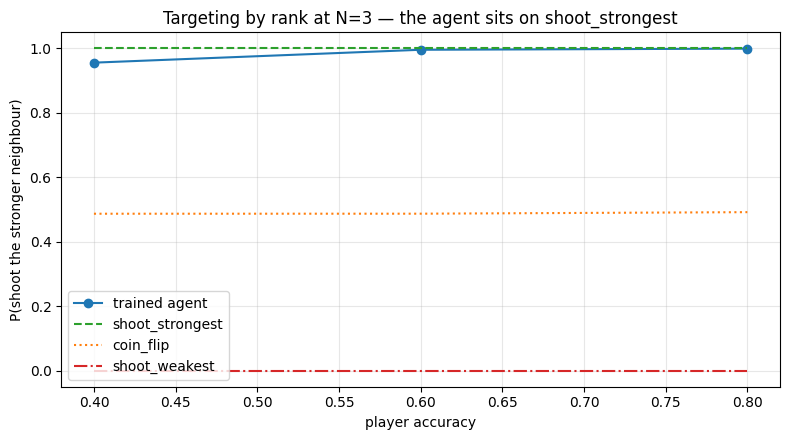

In [25]:
figure, axis = plt.subplots(figsize=(8, 4.5))
ranks = [0.4, 0.6, 0.8]
axis.plot(ranks, [agent_targeting[a] for a in ranks], "o-",
          color="tab:blue", label="trained agent")
for name, colour, style in [("shoot_strongest", "tab:green", "--"),
                            ("coin_flip", "tab:orange", ":"),
                            ("shoot_weakest", "tab:red", "-.")]:
    series = []
    for accuracy in ranks:
        rate, stronger, decisions = targeting_rate(calibration[name], accuracy=accuracy)
        series.append(rate)
    axis.plot(ranks, series, style, color=colour, label=name)

axis.set_xlabel("player accuracy")
axis.set_ylabel("P(shoot the stronger neighbour)")
axis.set_ylim(-0.05, 1.05)
axis.set_title("Targeting by rank at N=3 — the agent sits on shoot_strongest")
axis.legend()
axis.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## The three signatures, as measured

The table the rest of the investigation reads. Every row is a measurement made above,
not a description written by hand.

In [26]:
def signature_of(records, alive_records=None):
    """The three columns that make up a targeting signature."""
    low, _, _ = targeting_rate(records, accuracy=0.4)
    mid, _, _ = targeting_rate(records, accuracy=0.6)
    high, _, _ = targeting_rate(records, accuracy=0.8)
    extremes = (low + high) / 2
    if alive_records is None:
        survivor_spread = None
    else:
        rows = targeting_by_alive(alive_records)
        survivor_spread = (max(r[0] for r in rows.values())
                           - min(r[0] for r in rows.values()))
    return extremes, mid, survivor_spread


print("%-24s %10s %10s %14s   %s"
      % ("policy", "extremes", "middle", "surv. spread", "what it is"))

references = [
    ("shoot_strongest", calibration["shoot_strongest"],
     n5_records["shoot_strongest"], "reference: high everywhere, flat"),
    ("coin_flip", calibration["coin_flip"],
     n5_records["coin_flip"], "reference: discriminates on nothing"),
    ("switch_at_three", calibration["switch_at_three"],
     n5_records["switch_at_three"], "reference: depends on survivors"),
]

reference_signatures = {}
for name, rank_records, alive_records, description in references:
    extremes, middle, survivor_spread = signature_of(rank_records, alive_records)
    reference_signatures[name] = (extremes, middle)
    print("%-24s %10.4f %10.4f %14.4f   %s"
          % (name, extremes, middle, survivor_spread, description))

agent_extremes, agent_middle, _ = signature_of(agent_records)
print("%-24s %10.4f %10.4f %14s   %s"
      % ("trained agent", agent_extremes, agent_middle, "not measurable",
         "measured, N=3 has one row"))

policy                     extremes     middle   surv. spread   what it is
shoot_strongest              1.0000     1.0000         0.0000   reference: high everywhere, flat
coin_flip                    0.4894     0.4871         0.0180   reference: discriminates on nothing
switch_at_three              1.0000     1.0000         1.0000   reference: depends on survivors
trained agent                0.9777     0.9959 not measurable   measured, N=3 has one row


**Which reference the agent resembles is computed, not asserted.** Naming the row after
a conclusion would make the table agree with itself.

In [27]:
distances = {}
for name in reference_signatures:
    reference_extremes, reference_middle = reference_signatures[name]
    distances[name] = (abs(agent_extremes - reference_extremes)
                       + abs(agent_middle - reference_middle)) / 2

closest = min(distances, key=distances.get)
print("distance from each reference:")
for name in sorted(distances, key=distances.get):
    print("   %-18s %.4f" % (name, distances[name]))
print()

tied = []
for name in distances:
    if abs(distances[name] - distances[closest]) < 1e-9:
        tied.append(name)
if len(tied) > 1:
    print("TIED at", format(distances[closest], ".4f") + ":", sorted(tied))
    print("Not an ambiguity to resolve -- at N=3 those references ARE the same policy,")
    print("which is why their rank columns above are identical. Reporting one of them")
    print("as 'the closest' without saying so would invent a distinction.")
else:
    print("closest:", closest, "at", format(distances[closest], ".4f"))
print()
if closest == "shoot_strongest":
    print("At N=3 that is the equilibrium as well, so this measurement cannot separate")
    print("'matched the equilibrium' from 'imitated a heuristic'. The two policies are")
    print("identical here. Step 6 is the first player count at which they differ.")
else:
    print("The agent is closer to a reference that is NOT the N=3 equilibrium, which at")
    print("N=3 would be a disagreement with the known answer rather than a finding.")

print()
print("The equilibrium's own signature -- extremes near 1.0, middle near 0.3, varying")
print("as players die -- has no example above, because at N=3 it coincides with")
print("shoot_strongest. It first becomes visible at N=5.")

distance from each reference:
   shoot_strongest    0.0132
   switch_at_three    0.0132
   coin_flip          0.4985

TIED at 0.0132: ['shoot_strongest', 'switch_at_three']
Not an ambiguity to resolve -- at N=3 those references ARE the same policy,
which is why their rank columns above are identical. Reporting one of them
as 'the closest' without saying so would invent a distinction.

At N=3 that is the equilibrium as well, so this measurement cannot separate
'matched the equilibrium' from 'imitated a heuristic'. The two policies are
identical here. Step 6 is the first player count at which they differ.

The equilibrium's own signature -- extremes near 1.0, middle near 0.3, varying
as players die -- has no example above, because at N=3 it coincides with
shoot_strongest. It first becomes visible at N=5.


## Reproducibility

The same measurement run twice from the same seed. A step that cannot reproduce itself
cannot support a claim.

In [28]:
def measure_once():
    fresh = GruelEnv(n=3, reward="terminal", seating="ranked", seed=9000)
    records = play_episodes(fresh, shoot_strongest, 500)
    rate, stronger, decisions = targeting_rate(records)
    rows = targeting_by_alive(records)
    return (round(rate, 10), decisions, sorted(rows))


first = measure_once()
second = measure_once()

print("first :", first)
print("second:", second)
print("identical:", first == second)

first : (1.0, 852, [3])
second: (1.0, 852, [3])
identical: True
